# Bước 6. Modeling and Model Comparison: mốc so sánh, mười mô hình, thang đặc trưng, kiểm định và bốn thí nghiệm bổ sung

Bước này đi theo đúng thứ tự của phương pháp. Mục 6.1 tới 6.8 là phần chính: chốt cách chia và bộ đặc trưng, lập mốc quy tắc viết tay, chạy mười mô hình trên thang bảy bộ đặc trưng với năm seed, đo kết quả trên toàn bộ tập kiểm thử và riêng nhóm trang chủ, rồi kiểm định.
Mục 6.9 tới 6.12 là **bốn thí nghiệm bổ sung**: chia theo tên miền, dò tham số, TLD chưa thấy, và chi phí cùng độ quan trọng của đặc trưng. Mục 6.13 ghi bảng LaTeX và các con số của bài báo.

| STT | Mục | Việc làm | Tệp kết quả trong `Outputs` |
|---|---|---|---|
| 1 | 6.1 | Kiểm tra cách chia và thang bảy bộ đặc trưng | |
| 2 | 6.2 | Mốc không cần huấn luyện: ba quy tắc viết tay | `table_rules.csv` |
| 3 | 6.3 | Mười mô hình x bảy bộ đặc trưng x năm seed (350 lần huấn luyện) | `results_ladder.csv`, `scores_seed0.parquet` |
| 4 | 6.4 | Bảng kết quả với đủ đặc trưng (câu hỏi 2) và biểu đồ cột | `table_main.csv` |
| 5 | 6.5 | Toàn bộ tập kiểm thử so với nhóm trang chủ, biểu đồ quả tạ | `table_homepage.csv` |
| 6 | 6.6 | Thang đặc trưng (câu hỏi 3), biểu đồ cột ghép | `table_ladder.csv`, `table_ladder_by_model.csv` |
| 7 | 6.7 | Kiểm định McNemar với Holm, khoảng tin cậy bootstrap | `results_tests.csv`, `results_bootstrap_homepage.csv` |
| 8 | 6.8 | Ghi các con số của phần chính | `paper_numbers.csv` |
| 9 | 6.9 | **Bổ sung 1:** chia theo tên miền | `results_domain_split.csv`, `table_domain_vs_stratified.csv` |
| 10 | 6.10 | **Bổ sung 2:** dò tham số trên validation | `results_tuning.csv`, `table_tuned_vs_fixed.csv` |
| 11 | 6.11 | **Bổ sung 3:** TLD chưa thấy | `results_unseen_tld.csv`, `table_unseen_tld.csv` |
| 12 | 6.12 | **Bổ sung 4:** kích thước, thời gian và độ quan trọng của đặc trưng | `table_cost.csv`, `table_permutation_importance.csv` |
| 13 | 6.13 | Ghi bảng LaTeX và tệp con số | `Paper/tables/*.tex`, `paper_numbers.csv` |

**Cách chia của phần chính (hai câu):** mỗi seed chia phân tầng theo nhãn thành 60% huấn luyện, 20% validation và 20% kiểm thử (Bước 2, mục 2.9). Mô hình học trên tập huấn luyện, ngưỡng báo động đặt trên tập validation sao cho nhiều nhất 1% địa chỉ hợp lệ bị chặn, và mọi con số báo cáo đều tính trên tập kiểm thử.

**Các chỉ số.** Mũi tên ↑ nghĩa là càng cao càng tốt, ↓ là càng thấp càng tốt.

| STT | Chỉ số | Ý nghĩa |
|---|---|---|
| 1 | Tỷ lệ bắt được ở 1% báo động giả ↑ | Trong các địa chỉ lừa đảo của tập kiểm thử, bao nhiêu phần trăm bị chặn khi ngưỡng được đặt cho nhiều nhất 1% địa chỉ hợp lệ của tập validation bị chặn. Đây là chỉ số chính của đề tài |
| 2 | Báo động giả thực tế ↓ | Tỷ lệ địa chỉ hợp lệ của tập kiểm thử bị chặn ở ngưỡng ấy. Phải ở quanh 1% |
| 3 | ROC-AUC ↑ | Xác suất một địa chỉ lừa đảo ngẫu nhiên có điểm cao hơn một địa chỉ hợp lệ ngẫu nhiên. 0,5 là đoán bừa, 1 là tách trọn. Không phụ thuộc ngưỡng và tỷ lệ hai lớp |
| 4 | PR-AUC ↑ | Diện tích dưới đường độ chính xác và độ phủ của lớp lừa đảo |
| 5 | Brier ↓ | Sai số bình phương trung bình của xác suất dự báo. SVM tuyến tính không cho xác suất nên để trống |
| 6 | Độ chính xác và F1 ↑ | Ở ngưỡng mặc định (xác suất 0,5), chỉ để so với các bài đã công bố |

**Về thời gian chạy:** mục 6.3 huấn luyện 350 mô hình trên khoảng 141 nghìn dòng mỗi lần, mất khoảng 35 phút trên máy hai nhân, và cả notebook chạy lần đầu mất khoảng một tiếng rưỡi (k-NN chiếm gần một nửa vì phải tính khoảng cách tới mọi dòng huấn luyện). Kết quả được lưu vào `Outputs`, nên những lần chạy sau notebook đọc lại kết quả thay vì chạy lại. Đặt `RERUN = True` ở ô đầu để chạy lại từ đầu.

Ô dưới nạp thư viện, đặt kiểu hình, khai báo thang bảy bộ đặc trưng, mười mô hình và các hàm dùng chung (điểm số, ngưỡng 1% báo động giả, các chỉ số, huấn luyện và chấm một mô hình, tóm tắt qua năm seed). Ô này in kích thước bảng và số cột của từng bộ đặc trưng.

In [1]:
import os
os.environ["PYTHONWARNINGS"] = "ignore"                  # ẩn cảnh báo hội tụ của MLP và logistic
import json
import time
import pickle
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, f1_score
from sklearn.inspection import permutation_importance
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from style import *
setup()
warnings.filterwarnings("ignore")
plt.rcParams.update({"font.size": 8})
OUT = "../Outputs/"
os.makedirs("../Paper/figs", exist_ok=True)
os.makedirs("../Paper/tables", exist_ok=True)
pd.set_option("display.width", 250)
pd.set_option("display.float_format", lambda v: f"{v:.6g}")
RERUN = False                                          # True: chạy lại mọi mô hình; False: đọc kết quả đã lưu nếu có
SEEDS = [0, 1, 2, 3, 4]
FPR = 0.01                                             # ngân sách báo động giả: nhiều nhất 1% địa chỉ hợp lệ bị chặn
NUMBERS = []                                           # các con số sẽ trích trong bài báo
START = time.time()

df = pd.read_parquet(OUT + "phishing_model_table.parquet")
groups = json.load(open(OUT + "feature_groups.json", encoding="utf-8"))
SHORTCUT, ADDRESS, PAGE, PREFIX_BLIND = groups["shortcut"], groups["address"], groups["page"], groups["prefix_blind"]
TLD_STATS = ["TLDLegitimateProb", "URLCharProb"]
SETS = {
    "S1 all features": SHORTCUT + ADDRESS + PAGE,
    "S2 without similarity index": ADDRESS + PAGE,
    "S3 address and similarity index": SHORTCUT + ADDRESS,
    "S4 address only": ADDRESS,
    "S5 address without TLD statistics": [c for c in ADDRESS if c not in TLD_STATS],
    "S6 page only": PAGE,
    "S7 prefix blind": PREFIX_BLIND,
}


def note(section, name, value):
    """Ghi lại một con số sẽ được trích trong phần chữ của bài báo."""
    NUMBERS.append(dict(paper_section=section, quantity=name, value=value))


def log_scaled(model):
    """log(1 + x) rồi chuẩn hoá, cho mô hình tuyến tính, k-NN và MLP (quyết định của Bước 4, mục 4.1)."""
    return make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), model)


def make_models(seed):
    """Mười mô hình thuộc bốn họ, tham số chốt trước."""
    return {
        "Logistic": log_scaled(LogisticRegression(max_iter=1000)),
        "Linear SVM": log_scaled(LinearSVC(C=1.0, random_state=seed)),
        "k-NN": log_scaled(KNeighborsClassifier(n_neighbors=15)),
        "Decision tree": DecisionTreeClassifier(max_depth=12, min_samples_leaf=5, random_state=seed),
        "Random forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=seed),
        "Extra trees": ExtraTreesClassifier(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=seed),
        "HistGB": HistGradientBoostingClassifier(max_iter=200, random_state=seed),
        "LightGBM": LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=seed, verbose=-1),
        "XGBoost": XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8, tree_method="hist", random_state=seed, n_jobs=2),
        "Small MLP": log_scaled(MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=200, early_stopping=True, random_state=seed)),
    }


MODELS = list(make_models(0))
FAMILY = {"Logistic": "linear", "Linear SVM": "linear", "k-NN": "neighbours", "Decision tree": "trees", "Random forest": "trees", "Extra trees": "trees",
          "HistGB": "boosting", "LightGBM": "boosting", "XGBoost": "boosting", "Small MLP": "neural network"}


def score(model, X):
    """Điểm số càng cao càng giống lừa đảo; SVM tuyến tính không có xác suất nên dùng khoảng cách tới mặt phân cách."""
    return model.predict_proba(X)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X)


def threshold_at(valid_scores, valid_y):
    """Ngưỡng đặt trên tập validation: nhiều nhất 1% địa chỉ hợp lệ có điểm lớn hơn ngưỡng."""
    return np.quantile(valid_scores[valid_y == 0], 1 - FPR, method="higher")


def metrics(y, s, t, has_proba, prefix=""):
    """Các chỉ số trên một tập: ROC-AUC, PR-AUC, Brier, tỷ lệ bắt được và báo động giả ở ngưỡng t, độ chính xác và F1 ở ngưỡng mặc định."""
    y = np.asarray(y)
    flag = s > t
    default = s >= 0.5 if has_proba else s >= 0
    out = {"roc_auc": roc_auc_score(y, s) if len(set(y)) > 1 else np.nan, "pr_auc": average_precision_score(y, s) if len(set(y)) > 1 else np.nan,
           "brier": brier_score_loss(y, s) if has_proba else np.nan, "caught": flag[y == 1].mean() if (y == 1).any() else np.nan,
           "false_alarm": flag[y == 0].mean() if (y == 0).any() else np.nan, "accuracy": (default == y).mean(), "f1": f1_score(y, default) if (y == 1).any() else np.nan}
    return {prefix + k: v for k, v in out.items()}


def fit_and_score(name, cols, train, valid, test, seed, groups_out=None):
    """Huấn luyện một mô hình, đặt ngưỡng trên validation, chấm trên tập kiểm thử và các nhóm con."""
    model = make_models(seed)[name]
    t0 = time.perf_counter()
    model.fit(train[cols], train.phishing)
    fit_s = time.perf_counter() - t0
    has_proba = hasattr(model, "predict_proba")
    t = threshold_at(score(model, valid[cols]), valid.phishing.to_numpy())
    s = score(model, test[cols])
    row = {"model": name, "family": FAMILY[name], "seed": seed, "train_s": fit_s, **metrics(test.phishing, s, t, has_proba)}
    for gname, mask in (groups_out or {}).items():
        row.update(metrics(test.phishing[mask], s[mask.to_numpy()], t, has_proba, prefix=gname + "_"))
    return row, model, s, t


def summarise(results, keys, cols=("roc_auc", "pr_auc", "brier", "caught", "false_alarm", "accuracy", "f1", "train_s")):
    """Trung bình và độ lệch chuẩn qua năm seed."""
    g = results.groupby(keys, sort=False)
    out = g[list(cols)].mean()
    for c in ["roc_auc", "caught"]:
        if c in cols:
            out[c + "_sd"] = g[c].std()
    return out.reset_index()


def split_of(kind, seed):
    """Ba tập của một cách chia: kind là 'split' (phân tầng) hoặc 'gsplit' (theo tên miền)."""
    col = f"{kind}_s{seed}"
    return df[df[col] == "train"], df[df[col] == "valid"], df[df[col] == "test"]


print("Bảng mô hình:", df.shape, "| số mô hình:", len(MODELS), "| bộ đặc trưng:", {k: len(v) for k, v in SETS.items()})

Bảng mô hình: (235370, 89) | số mô hình: 10 | bộ đặc trưng: {'S1 all features': 50, 'S2 without similarity index': 49, 'S3 address and similarity index': 22, 'S4 address only': 21, 'S5 address without TLD statistics': 19, 'S6 page only': 28, 'S7 prefix blind': 14}


## 6.1 Cách chia và thang bảy bộ đặc trưng
Ô dưới in kích thước ba tập của năm seed (chia phân tầng của Bước 2) và số cột của bảy bộ đặc trưng.
Cách đọc: bảy bộ được xếp từ nhiều thông tin tới ít thông tin. Bộ S1 là thiết lập các bài khác dùng. Bộ S2 bỏ chỉ số tương đồng, S3 và S4 chỉ giữ đặc trưng biết trước khi mở trang, S5 bỏ thêm hai cột thống kê TLD, S6 chỉ giữ đặc trưng trang, và S7 là bộ không thấy tiền tố nhóm tự tính ở Bước 2.

In [2]:
rows = []
for seed in SEEDS:
    train, valid, test = split_of("split", seed)
    rows.append(dict(seed=seed, train=len(train), valid=len(valid), test=len(test), test_phishing=int(test.phishing.sum()), test_legitimate=int((test.phishing == 0).sum()),
                     test_homepage=int(test.homepage_only.sum()), test_homepage_phishing=int((test.homepage_only & test.phishing).sum())))
print(pd.DataFrame(rows).to_string(index=False))
print("\nThang bảy bộ đặc trưng:")
for name, cols in SETS.items():
    print(f"  {name:36s} {len(cols):2d} cột", "| có IsHTTPS" if "IsHTTPS" in cols else "", "| có chỉ số tương đồng" if "URLSimilarityIndex" in cols else "")
note("Method", "test addresses per seed", rows[0]["test"])
note("Method", "test homepage addresses per seed", rows[0]["test_homepage"])

 seed  train  valid  test  test_phishing  test_legitimate  test_homepage  test_homepage_phishing
    0 141222  47074 47074          20104            26970          35194                    8224
    1 141222  47074 47074          20104            26970          35119                    8149
    2 141222  47074 47074          20104            26970          34979                    8009
    3 141222  47074 47074          20104            26970          35104                    8134
    4 141222  47074 47074          20104            26970          35021                    8051

Thang bảy bộ đặc trưng:
  S1 all features                      50 cột | có IsHTTPS | có chỉ số tương đồng
  S2 without similarity index          49 cột | có IsHTTPS 
  S3 address and similarity index      22 cột | có IsHTTPS | có chỉ số tương đồng
  S4 address only                      21 cột | có IsHTTPS 
  S5 address without TLD statistics    19 cột | có IsHTTPS 
  S6 page only                         28 cột  
 

**Nhận xét:** năm seed có cùng kích thước ba tập (141.222, 47.074 và 47.074 dòng) và cùng 20.104 địa chỉ lừa đảo trong tập kiểm thử, vì chia phân tầng theo nhãn. Phần trang chủ của tập kiểm thử có khoảng 35.000 dòng, trong đó khoảng 8.000 địa chỉ lừa đảo.
Năm bộ đầu đều có `IsHTTPS`, và bộ S1, S3 có thêm chỉ số tương đồng. Chỉ hai bộ S6 (trang) và S7 (không thấy tiền tố) không có `IsHTTPS`.

## 6.2 Mốc không cần huấn luyện: ba quy tắc viết tay
Ô dưới chấm ba quy tắc trên đúng tập kiểm thử của năm seed: không bắt đầu bằng `https://www.`, gộp với có đường dẫn, và chỉ số tương đồng dưới 100. Quy tắc chỉ cho 0 hoặc 1 nên ROC-AUC của nó bằng trung bình của tỷ lệ bắt được và tỷ lệ không chặn nhầm.
Cách đọc: đây là các mốc mà mười mô hình phải vượt. Bảng lưu ở `Outputs/table_rules.csv`.

In [3]:
rule_rows = []
for seed in SEEDS:
    _, _, test = split_of("split", seed)
    for name, flag in [("Rule: not https://www.", 1 - test.starts_https_www), ("Rule: not https://www. or has a path", ((test.starts_https_www == 0) | (test.has_path == 1)).astype(int)),
                       ("Rule: similarity index < 100", (test.URLSimilarityIndex < 100).astype(int))]:
        y, f = test.phishing.to_numpy(), flag.to_numpy()
        home = test.homepage_only.to_numpy() == 1
        rule_rows.append(dict(model=name, seed=seed, roc_auc=roc_auc_score(y, f), caught=f[y == 1].mean(), false_alarm=f[y == 0].mean(), accuracy=(f == y).mean(), f1=f1_score(y, f),
                              home_roc_auc=roc_auc_score(y[home], f[home]), home_caught=f[home & (y == 1)].mean()))
rules = pd.DataFrame(rule_rows)
rule_table = rules.groupby("model", sort=False).agg(["mean", "std"]).drop(columns="seed")
rule_table.columns = [f"{a}_{b}" for a, b in rule_table.columns]
rule_table.round(5).to_csv(OUT + "table_rules.csv")
print(rule_table[["roc_auc_mean", "caught_mean", "caught_std", "false_alarm_mean", "accuracy_mean", "home_caught_mean"]].round(4).to_string())
best_rule = rule_table.loc["Rule: not https://www. or has a path"]
note("Results", "rule prefix-or-path accuracy (%)", round(100 * best_rule.accuracy_mean, 2))
note("Results", "rule prefix-or-path caught (%)", round(100 * best_rule.caught_mean, 2))
note("Results", "rule prefix accuracy (%)", round(100 * rule_table.loc["Rule: not https://www."].accuracy_mean, 2))

                                      roc_auc_mean  caught_mean  caught_std  false_alarm_mean  accuracy_mean  home_caught_mean
model                                                                                                                         
Rule: not https://www.                      0.9878       0.9757      0.0008                 0         0.9896            0.9836
Rule: not https://www. or has a path        0.9967       0.9934      0.0002                 0         0.9972            0.9836
Rule: similarity index < 100                0.9963       0.9925      0.0005                 0         0.9968            0.9821


**Nhận xét:** trên tập kiểm thử của năm seed, quy tắc tiền tố đạt 98,96% độ chính xác và bắt 97,57% địa chỉ lừa đảo. Quy tắc hai điều kiện đạt 99,72% và bắt 99,34%. Quy tắc chỉ số tương đồng đạt 99,68% và bắt 99,25%. Cả ba đều không báo động giả nào ở cả năm seed, và độ lệch chuẩn qua năm seed dưới 0,1 điểm phần trăm.
Trên phần trang chủ, quy tắc tiền tố vẫn bắt 98,36% địa chỉ lừa đảo. Hai điều kiện viết tay vì vậy là một mốc rất cao: mô hình nào muốn hơn phải đạt trên 99,72% độ chính xác, trong khi quy tắc không cần huấn luyện và không chặn nhầm địa chỉ hợp lệ nào.

## 6.3 Mười mô hình trên thang bảy bộ đặc trưng, năm seed
Ô dưới huấn luyện mười mô hình trên bảy bộ đặc trưng với năm seed. Mỗi lần huấn luyện: học trên tập huấn luyện, đặt ngưỡng trên validation, chấm trên tập kiểm thử và riêng trên phần trang chủ của tập kiểm thử. Điểm số của seed 0 cho ba bộ S1, S4, S7 được giữ lại để kiểm định ở mục 6.7.
Cách đọc: mỗi dòng in ra là một bộ đặc trưng của một seed, kèm thời gian. Nếu kết quả đã được lưu từ lần chạy trước, ô chỉ đọc lại.

In [4]:
LADDER_FILE, SCORES_FILE = OUT + "results_ladder.csv", OUT + "scores_seed0.parquet"
if os.path.exists(LADDER_FILE) and os.path.exists(SCORES_FILE) and not RERUN:
    ladder = pd.read_csv(LADDER_FILE)
    scores0 = pd.read_parquet(SCORES_FILE)
    print("Đọc kết quả đã lưu:", LADDER_FILE, ladder.shape, "| đặt RERUN = True để chạy lại")
else:
    rows, kept = [], []
    for seed in SEEDS:
        train, valid, test = split_of("split", seed)
        home = test.homepage_only == 1
        for set_name, cols in SETS.items():
            t_set = time.time()
            for name in MODELS:
                row, model, s, t = fit_and_score(name, cols, train, valid, test, seed, {"home": home})
                rows.append({"feature_set": set_name, **row})
                if seed == 0 and set_name in ("S1 all features", "S4 address only", "S7 prefix blind"):
                    kept.append(pd.DataFrame({"row_id": test.row_id.to_numpy(), "feature_set": set_name, "model": name, "score": s, "flag": s > t}))
            print(f"seed {seed} | {set_name:36s} | {time.time() - t_set:6.1f} s | đã chạy {time.time() - START:7.0f} s", flush=True)
    ladder = pd.DataFrame(rows)
    scores0 = pd.concat(kept, ignore_index=True)
    ladder.to_csv(LADDER_FILE, index=False)
    scores0.to_parquet(SCORES_FILE, index=False)
print("Số lần huấn luyện:", len(ladder), "=", len(SETS), "bộ đặc trưng x", len(MODELS), "mô hình x", len(SEEDS), "seed")

Đọc kết quả đã lưu: ../Outputs/results_ladder.csv (350, 19) | đặt RERUN = True để chạy lại
Số lần huấn luyện: 350 = 7 bộ đặc trưng x 10 mô hình x 5 seed


**Nhận xét:** 350 lần huấn luyện mất khoảng 35 phút trên máy hai nhân, mỗi bộ đặc trưng của một seed từ 45 tới 77 giây. Kết quả được lưu vào `Outputs/results_ladder.csv` và `Outputs/scores_seed0.parquet`, nên các lần chạy sau ô chỉ đọc lại.

## 6.4 Câu hỏi 2: mười mô hình với đủ đặc trưng
Ô dưới tóm tắt mười mô hình trên bộ S1 (đủ 50 đặc trưng, thiết lập của các bài đã công bố): trung bình năm seed của mọi chỉ số, kèm độ lệch chuẩn của ROC-AUC và tỷ lệ bắt được.
Cách đọc: chênh lệch giữa hai mô hình nhỏ hơn độ lệch chuẩn thì chưa nói được mô hình nào hơn. Bảng lưu ở `Outputs/table_main.csv`.

In [5]:
main = summarise(ladder[ladder.feature_set == "S1 all features"], ["model"])
main.round(5).to_csv(OUT + "table_main.csv", index=False)
print(main[["model", "roc_auc", "roc_auc_sd", "pr_auc", "brier", "caught", "caught_sd", "false_alarm", "accuracy", "f1", "train_s"]].round(4).to_string(index=False))
print("\nKhoảng ROC-AUC giữa mô hình tốt nhất và kém nhất: %.4f | khoảng độ chính xác: %.4f" % (main.roc_auc.max() - main.roc_auc.min(), main.accuracy.max() - main.accuracy.min()))
print("Mô hình có độ chính xác trung bình cao hơn quy tắc hai điều kiện (%.2f%%):" % (100 * best_rule.accuracy_mean), main[main.accuracy > best_rule.accuracy_mean].model.tolist())
note("Results", "S1 ROC-AUC range across models", f"{main.roc_auc.min():.4f} to {main.roc_auc.max():.4f}")
note("Results", "S1 accuracy range across models (%)", f"{100 * main.accuracy.min():.2f} to {100 * main.accuracy.max():.2f}")
note("Results", "S1 caught at 1% false alarms, range (%)", f"{100 * main.caught.min():.2f} to {100 * main.caught.max():.2f}")

        model  roc_auc  roc_auc_sd  pr_auc  brier  caught  caught_sd  false_alarm  accuracy     f1  train_s
     Logistic        1           0       1 0.0001       1          0       0.0097    0.9999 0.9999   0.8944
   Linear SVM        1           0       1    NaN       1          0       0.0097    0.9999 0.9999    1.378
         k-NN   0.9999           0  0.9998 0.0008  0.9997     0.0001        0.003    0.9989 0.9988   0.4387
Decision tree        1           0       1      0       1          0            0         1      1   0.7219
Random forest        1           0       1 0.0001       1          0       0.0101         1      1   4.8045
  Extra trees        1           0       1 0.0004       1          0       0.0101    0.9999 0.9999   4.5078
       HistGB        1           0       1      0       1          0       0.0099         1      1    2.807
     LightGBM        1           0       1      0       1          0       0.0099         1      1   2.0462
      XGBoost        1      

**Nhận xét:** với đủ 50 đặc trưng, cả mười mô hình đều chạm trần: ROC-AUC từ 0,9999 tới 1,0000, độ chính xác từ 99,89% (k-NN) tới 100,00%, và bắt từ 99,97% tới 100% địa chỉ lừa đảo ở mức 1% báo động giả. Độ lệch chuẩn qua năm seed gần như bằng 0 (lớn nhất 0,0001, ở tỷ lệ bắt của k-NN).. Khoảng cách giữa mô hình tốt nhất và kém nhất chỉ 0,0001 về ROC-AUC và 0,11 điểm phần trăm về độ chính xác.
Cả mười mô hình đều cao hơn quy tắc hai điều kiện (99,72%), nhưng chỉ cao hơn chưa tới 0,3 điểm phần trăm, và cái giá là 50 đặc trưng, trong đó có chỉ số tương đồng và 28 đặc trưng cần tải trang về.
**Trả lời câu hỏi 2:** với cách chia phân tầng và đủ đặc trưng, mười mô hình không tách được nhau. Thiết lập mà các bài đã công bố dùng không phân biệt được mô hình nào tốt hơn.

**Biểu đồ cột ngang. Vì sao chọn dạng này:** mỗi mô hình có một độ chính xác, và cột ngang cho phép viết đủ tên mô hình. Đường đứt san hô là độ chính xác của quy tắc hai điều kiện, để thấy ngay mô hình nào vượt mốc. Trục ngang bắt đầu ở 99,5% vì mọi con số đều nằm sát 100%.

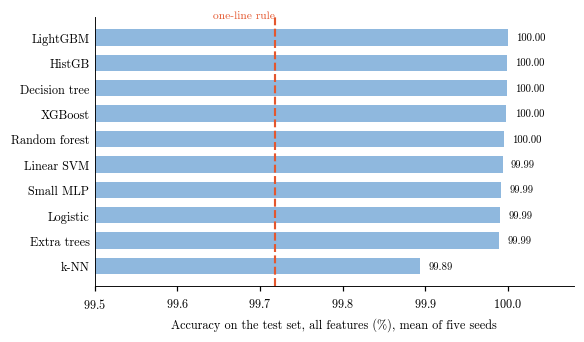

In [6]:
order = main.sort_values("accuracy")
fig, ax = plt.subplots(figsize=(5.2, 3.0), layout="constrained")
ax.barh(order.model, 100 * order.accuracy, color=SKY, height=0.65)
ax.axvline(100 * best_rule.accuracy_mean, color=OURS, lw=1.4, ls="--")
ax.text(100 * best_rule.accuracy_mean, len(order) - 0.3, " one-line rule", color=OURS, va="bottom", ha="right", fontsize=7.5)
for k, v in enumerate(100 * order.accuracy):
    ax.text(v + 0.01, k, f"{v:.2f}", va="center", fontsize=7, fontfamily=BOLD)
ax.set_xlim(99.5, 100.08)
ax.set_xlabel("Accuracy on the test set, all features (%), mean of five seeds")
ax.tick_params(axis="y", length=0)
save(fig, "b6_models_accuracy")

## 6.5 Toàn bộ tập kiểm thử so với nhóm trang chủ
Ô dưới so ROC-AUC và tỷ lệ bắt được của mười mô hình trên toàn bộ tập kiểm thử và riêng phần trang chủ, cho ba bộ đặc trưng S1, S4, S7. Phần trang chủ chứa toàn bộ địa chỉ hợp lệ, nên ngưỡng và báo động giả không đổi, chỉ tập địa chỉ lừa đảo đổi.
Cách đọc: hai bảng in ra là ROC-AUC và tỷ lệ bắt được trên nhóm trang chủ. Bảng đầy đủ lưu ở `Outputs/table_homepage.csv`.

In [7]:
focus = ladder[ladder.feature_set.isin(["S1 all features", "S4 address only", "S7 prefix blind"])]
home_table = summarise(focus, ["feature_set", "model"], cols=("roc_auc", "home_roc_auc", "caught", "home_caught", "false_alarm"))
home_table.round(5).to_csv(OUT + "table_homepage.csv", index=False)
print(home_table.pivot(index="model", columns="feature_set", values="home_roc_auc").round(4).to_string())
print()
print(home_table.pivot(index="model", columns="feature_set", values="home_caught").round(4).to_string())
s7 = home_table[home_table.feature_set == "S7 prefix blind"]
note("Results", "S7 ROC-AUC on all test addresses, best model", round(s7.roc_auc.max(), 4))
note("Results", "S7 ROC-AUC on homepage-only test addresses, range", f"{s7.home_roc_auc.min():.4f} to {s7.home_roc_auc.max():.4f}")
note("Results", "S7 caught at 1% false alarms on homepage-only addresses, best (%)", round(100 * s7.home_caught.max(), 2))

feature_set    S1 all features  S4 address only  S7 prefix blind
model                                                           
Decision tree                1           0.9955           0.7354
Extra trees                  1           0.9966           0.7302
HistGB                       1           0.9972           0.7368
LightGBM                     1           0.9974           0.7369
Linear SVM                   1           0.9957           0.6641
Logistic                     1           0.9963           0.6633
Random forest                1            0.997           0.7356
Small MLP                    1           0.9967           0.7357
XGBoost                      1           0.9973           0.7371
k-NN                    0.9998           0.9954           0.7082

feature_set    S1 all features  S4 address only  S7 prefix blind
model                                                           
Decision tree                1           0.9893           0.2595
Extra trees             

**Nhận xét:** với bộ S1, nhóm trang chủ gần như không làm điểm số rơi (ROC-AUC từ 0,9998 ở k-NN tới 1,0000 ở các mô hình còn lại).. Với bộ S4, ROC-AUC trên nhóm trang chủ vẫn từ 0,9954 tới 0,9974 và các mô hình vẫn bắt từ 98,92% tới 99,18% địa chỉ lừa đảo là trang chủ. Lý do là S4 vẫn có `IsHTTPS`, mà trang chủ lừa đảo hầu như không dùng https (Bước 4, mục 4.10).
Với bộ S7, ROC-AUC rơi từ khoảng 0,86 tới 0,89 trên toàn bộ xuống 0,663 tới 0,737 trên nhóm trang chủ. Tỷ lệ bắt được rơi xuống 15,2% tới 26,0%: ở mức 1% báo động giả, mô hình tốt nhất chỉ bắt được khoảng một phần tư số trang chủ lừa đảo. Các mô hình cây và tăng cường (0,73 tới 0,74) hơn mô hình tuyến tính (0,66) rõ rệt.

**Biểu đồ quả tạ. Vì sao chọn dạng này:** mỗi mô hình có hai con số, trên toàn bộ và trên nhóm trang chủ. Thanh nối cho thấy ngay điểm số rơi bao nhiêu khi bỏ các địa chỉ có đường dẫn. Mười dòng dưới là bộ S4, mười dòng trên là bộ S7.

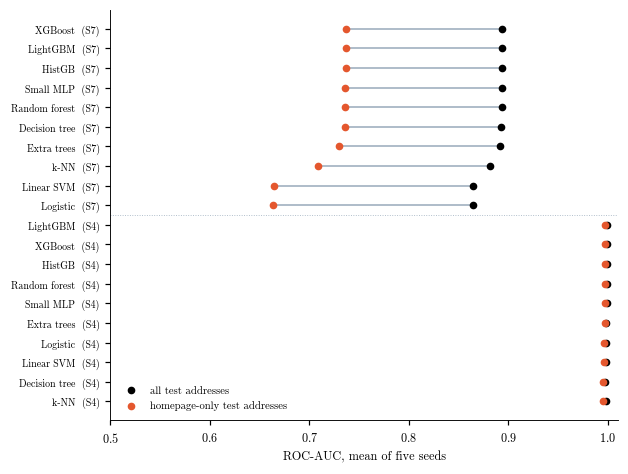

In [8]:
sub = home_table[home_table.feature_set.isin(["S4 address only", "S7 prefix blind"])].copy()
sub["label"] = sub.model + np.where(sub.feature_set.str.startswith("S4"), "  (S4)", "  (S7)")
sub = sub.sort_values(["feature_set", "home_roc_auc"])
fig, ax = plt.subplots(figsize=(5.6, 4.2), layout="constrained")
yy = np.arange(len(sub))
ax.hlines(yy, sub.home_roc_auc, sub.roc_auc, color=GREY, lw=1.2)
ax.scatter(sub.roc_auc, yy, color="black", s=16, label="all test addresses", zorder=3)
ax.scatter(sub.home_roc_auc, yy, color=OURS, s=16, label="homepage-only test addresses", zorder=3)
ax.axhline(9.5, color=GREY, lw=0.6, ls=":")
ax.set_yticks(yy)
ax.set_yticklabels(sub.label, fontsize=6.5)
ax.set_xlim(0.5, 1.01)
ax.set_xlabel("ROC-AUC, mean of five seeds")
ax.legend(frameon=False, fontsize=7, loc="lower left")
save(fig, "b6_homepage_dumbbell")

## 6.6 Câu hỏi 3: thang đặc trưng
Ô dưới gom kết quả theo bộ đặc trưng: ROC-AUC trung bình của mười mô hình, tỷ lệ bắt được trung bình và tốt nhất, cùng ROC-AUC trung bình và tỷ lệ bắt được tốt nhất trên nhóm trang chủ.
Cách đọc: đọc từ trên xuống, mỗi bậc bỏ bớt một phần thông tin. Bậc nào làm điểm số rơi mạnh thì phần bị bỏ ở bậc ấy là nơi điểm số dựa vào. Bảng lưu ở `Outputs/table_ladder.csv`.

In [9]:
lad = summarise(ladder, ["feature_set", "model"], cols=("roc_auc", "home_roc_auc", "caught", "home_caught", "false_alarm"))
by_set = lad.groupby("feature_set", sort=False).agg(n_features=("feature_set", lambda v: len(SETS[v.iloc[0]])), roc_auc_mean=("roc_auc", "mean"), caught_mean=("caught", "mean"),
                                                      caught_best=("caught", "max"), home_roc_auc_mean=("home_roc_auc", "mean"), home_caught_best=("home_caught", "max"))
by_set.round(5).to_csv(OUT + "table_ladder.csv")
lad.round(5).to_csv(OUT + "table_ladder_by_model.csv", index=False)
print(by_set.round(4).to_string())
for name in SETS:
    note("Results", f"{name}: mean ROC-AUC / best caught (%) / best homepage caught (%)",
         f"{by_set.loc[name, 'roc_auc_mean']:.4f} / {100 * by_set.loc[name, 'caught_best']:.2f} / {100 * by_set.loc[name, 'home_caught_best']:.2f}")

                                   n_features  roc_auc_mean  caught_mean  caught_best  home_roc_auc_mean  home_caught_best
feature_set                                                                                                               
S1 all features                            50             1            1            1                  1                 1
S2 without similarity index                49        0.9999       0.9999            1             0.9999                 1
S3 address and similarity index            22        0.9999       0.9997       0.9999             0.9997            0.9997
S4 address only                            21        0.9984       0.9955       0.9965             0.9965            0.9918
S5 address without TLD statistics          19        0.9982       0.9955       0.9964              0.996            0.9912
S6 page only                               28        0.9996       0.9975       0.9994             0.9995            0.9991
S7 prefix blind 

**Nhận xét:** đọc từ trên xuống, ba bậc đầu gần như không đổi gì: bỏ chỉ số tương đồng (S2) hay chỉ giữ đặc trưng địa chỉ cùng chỉ số tương đồng (S3) vẫn cho ROC-AUC 0,9999. Chỉ giữ 21 đặc trưng địa chỉ (S4) vẫn bắt 99,65% địa chỉ lừa đảo ở mức 1% báo động giả, và bỏ thêm hai cột thống kê TLD (S5) gần như không đổi (99,64%). Chỉ có đặc trưng trang (S6) cũng bắt 99,94%.
Bậc duy nhất làm điểm số sụp là S7, bộ không thấy tiền tố: ROC-AUC trung bình còn 0,8863, mô hình tốt nhất bắt 70,14% trên toàn bộ và 26,02% trên nhóm trang chủ, trong khi quy tắc hai điều kiện bắt 99,34% mà không báo động giả nào.
**Trả lời câu hỏi 3:** con số gần tuyệt đối còn gần như nguyên khi bỏ chỉ số tương đồng, khi chỉ giữ đặc trưng biết trước lúc mở trang, và khi bỏ thống kê TLD, vì mỗi bộ ấy vẫn còn một lối tắt khác (tiền tố trong `IsHTTPS` và độ dài tên miền, hoặc độ trống của trang). Khi bộ lọc không được thấy tiền tố và chỉ xét trang chủ, điểm số rơi xuống ROC-AUC khoảng 0,74 và chỉ bắt được khoảng một phần tư địa chỉ lừa đảo.

**Biểu đồ cột ghép. Vì sao chọn dạng này:** mỗi bộ đặc trưng có hai con số (toàn bộ và nhóm trang chủ). Hai cột đứng cạnh nhau cho thấy cả bậc thang lẫn khoảng rơi ở nhóm trang chủ. Đường đứt là tỷ lệ bắt được của quy tắc hai điều kiện, vốn không báo động giả nào.

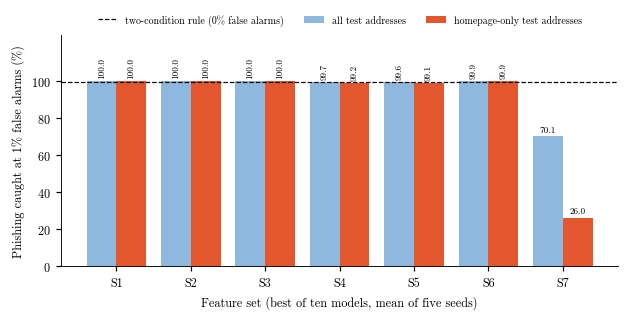

In [10]:
sets_short = [k.split(" ", 1)[0] for k in SETS]
best = lad.groupby("feature_set", sort=False)[["caught", "home_caught"]].max()
fig, ax = plt.subplots(figsize=(5.6, 2.8), layout="constrained")
x = np.arange(len(best))
b1 = ax.bar(x - 0.2, 100 * best.caught, 0.4, color=SKY, label="all test addresses")
b2 = ax.bar(x + 0.2, 100 * best.home_caught, 0.4, color=OURS, label="homepage-only test addresses")
for k in x:
    for dx, v in [(-0.2, best.caught.iloc[k]), (0.2, best.home_caught.iloc[k])]:
        ax.text(k + dx, 100 * v + 1.5, f"{100 * v:.1f}", ha="center", fontsize=6, fontfamily=BOLD, rotation=90 if v > 0.9 else 0, va="bottom")
rule_line = ax.axhline(100 * best_rule.caught_mean, color="black", lw=0.8, ls="--", label="two-condition rule (0% false alarms)")
ax.set_xticks(x)
ax.set_xticklabels(sets_short)
ax.set_ylim(0, 125)
ax.set_yticks([0, 20, 40, 60, 80, 100])
ax.set_ylabel("Phishing caught at 1% false alarms (%)")
ax.set_xlabel("Feature set (best of ten models, mean of five seeds)")
ax.legend(frameon=False, fontsize=6.5, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3)
save(fig, "b6_feature_ladder")

## 6.7 Kiểm định: mô hình có thật sự hơn quy tắc không
Ô dưới dùng kiểm định McNemar trên tập kiểm thử seed 0. Với mỗi mô hình trên bộ S1, ở ngưỡng mặc định (xác suất 0,5), ô đếm số địa chỉ mô hình đúng mà quy tắc hai điều kiện sai, và ngược lại. McNemar hỏi hai con số ấy có khác nhau thật không. Mười phép so được hiệu chỉnh Holm. Ở đây dùng ngưỡng mặc định chứ không dùng ngưỡng 1% báo động giả, vì quy tắc không báo động giả nào: ép mô hình chặn nhầm tới 1% rồi so số lỗi với quy tắc sẽ thiên vị quy tắc.
Cách đọc: `p_holm` dưới 0,05 nghĩa là khác biệt có ý nghĩa thống kê. Xem cột lỗi để biết bên nào hơn. Bảng lưu ở `Outputs/results_tests.csv`.

In [11]:
def mcnemar(a_correct, b_correct):
    """Kiểm định McNemar có hiệu chỉnh liên tục trên hai dãy đúng sai của cùng một tập."""
    b = int((a_correct & ~b_correct).sum())
    c = int((~a_correct & b_correct).sum())
    chi2 = (abs(b - c) - 1) ** 2 / (b + c) if b + c > 0 else 0.0
    return b, c, chi2, stats.chi2.sf(chi2, 1)


def holm(p):
    """Hiệu chỉnh Holm cho nhiều phép so sánh."""
    p = np.asarray(p)
    order = np.argsort(p)
    adj = np.empty_like(p)
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (len(p) - rank) * p[i])
        adj[i] = min(running, 1.0)
    return adj


_, _, test0 = split_of("split", 0)
y0 = test0.set_index("row_id").phishing
rule0 = (((test0.starts_https_www == 0) | (test0.has_path == 1)).astype(int)).to_numpy() == y0.to_numpy()
tests = []
for name in MODELS:
    part = scores0[(scores0.feature_set == "S1 all features") & (scores0.model == name)].set_index("row_id").loc[y0.index]
    cut = 0.0 if name == "Linear SVM" else 0.5                                     # ngưỡng mặc định của mô hình, như các bài đã công bố
    model_correct = (part.score.to_numpy() >= cut).astype(int) == y0.to_numpy()
    b, c, chi2, p = mcnemar(model_correct, rule0)
    tests.append(dict(model=name, model_errors=int((~model_correct).sum()), rule_errors=int((~rule0).sum()), model_right_rule_wrong=b, rule_right_model_wrong=c, chi2=chi2, p=p))
tests = pd.DataFrame(tests)
tests["p_holm"] = holm(tests.p)
tests.round(6).to_csv(OUT + "results_tests.csv", index=False)
print("McNemar trên tập kiểm thử seed 0: mỗi mô hình (bộ S1, ngưỡng mặc định) so với quy tắc hai điều kiện")
print(tests.round(4).to_string(index=False))
note("Results", "models significantly better than the two-condition rule after Holm (S1, seed 0, default threshold)", int(((tests.p_holm < 0.05) & (tests.model_errors < tests.rule_errors)).sum()))
note("Results", "test errors of the two-condition rule and of the models (S1, seed 0, default threshold)", f"{int((~rule0).sum())} vs {tests.model_errors.min()} to {tests.model_errors.max()}")

McNemar trên tập kiểm thử seed 0: mỗi mô hình (bộ S1, ngưỡng mặc định) so với quy tắc hai điều kiện
        model  model_errors  rule_errors  model_right_rule_wrong  rule_right_model_wrong    chi2  p  p_holm
     Logistic             5          132                     130                       3 119.368  0       0
   Linear SVM             4          132                     130                       2 122.189  0       0
         k-NN            46          132                     127                      41  43.006  0       0
Decision tree             1          132                     132                       1 127.068  0       0
Random forest             1          132                     132                       1 127.068  0       0
  Extra trees             3          132                     130                       1 125.069  0       0
       HistGB             0          132                     132                       0 130.008  0       0
     LightGBM             0         

**Nhận xét:** trên 47.074 địa chỉ kiểm thử của seed 0, quy tắc hai điều kiện sai 132 địa chỉ, còn mười mô hình trên bộ S1 sai từ 0 (HistGB, LightGBM) tới 46 địa chỉ (k-NN) tới 46 địa chỉ (k-NN). Cả mười phép so đều có p sau hiệu chỉnh Holm dưới 0,001, và ở cả mười phép so mô hình là bên ít lỗi hơn.
Vậy với đủ 50 đặc trưng, mô hình hơn quy tắc một cách có ý nghĩa thống kê, nhưng phần hơn chỉ là khoảng 130 địa chỉ trên 47.074 (0,28%), và nó đến từ chỉ số tương đồng cùng đặc trưng trang, cũng là những lối tắt (Bước 4, mục 4.2 và 4.14).

Ô dưới tính khoảng tin cậy bootstrap 95% của ROC-AUC trên nhóm trang chủ cho bộ S7, seed 0: lấy lại ngẫu nhiên có hoàn lại các địa chỉ của nhóm 500 lần và tính ROC-AUC mỗi lần.
Cách đọc: hai mô hình có khoảng tin cậy chồng nhau thì chưa nói được mô hình nào hơn.

In [12]:
rng = np.random.default_rng(0)
home0 = test0[test0.homepage_only == 1].set_index("row_id").phishing
B = 500
boot = []
for name in MODELS:
    part = scores0[(scores0.feature_set == "S7 prefix blind") & (scores0.model == name)].set_index("row_id").loc[home0.index]
    yv, sv = home0.to_numpy(), part.score.to_numpy()
    values = []
    for _ in range(B):
        idx = rng.integers(0, len(yv), len(yv))
        values.append(roc_auc_score(yv[idx], sv[idx]))
    boot.append(dict(model=name, home_roc_auc=roc_auc_score(yv, sv), ci_low=np.percentile(values, 2.5), ci_high=np.percentile(values, 97.5)))
boot = pd.DataFrame(boot).sort_values("home_roc_auc", ascending=False)
boot.round(4).to_csv(OUT + "results_bootstrap_homepage.csv", index=False)
print(f"Khoảng tin cậy bootstrap 95% ({B} lần lấy lại) của ROC-AUC trên nhóm trang chủ, bộ S7, seed 0:")
print(boot.round(4).to_string(index=False))
top = boot.iloc[0]
print("\nMô hình có khoảng tin cậy chồng với mô hình tốt nhất (%s):" % top.model, boot[boot.ci_high >= top.ci_low].model.tolist())

Khoảng tin cậy bootstrap 95% (500 lần lấy lại) của ROC-AUC trên nhóm trang chủ, bộ S7, seed 0:
        model  home_roc_auc  ci_low  ci_high
     LightGBM        0.7347  0.7278    0.741
      XGBoost        0.7346  0.7282   0.7409
       HistGB        0.7345  0.7283   0.7411
Decision tree        0.7334  0.7269   0.7407
Random forest        0.7329   0.726   0.7389
    Small MLP        0.7328  0.7261   0.7396
  Extra trees        0.7277  0.7212   0.7347
         k-NN        0.7097   0.703   0.7174
   Linear SVM        0.6643  0.6564   0.6724
     Logistic        0.6635  0.6562   0.6709

Mô hình có khoảng tin cậy chồng với mô hình tốt nhất (LightGBM): ['LightGBM', 'XGBoost', 'HistGB', 'Decision tree', 'Random forest', 'Small MLP', 'Extra trees']


**Nhận xét:** trên nhóm trang chủ với bộ S7, LightGBM có ROC-AUC cao nhất (0,7347, khoảng tin cậy 0,7278 tới 0,7410), nhưng khoảng tin cậy của nó chồng với sáu mô hình khác: HistGB, XGBoost, cây quyết định, random forest, MLP và extra trees. Ba mô hình còn lại thấp hơn rõ: k-NN (0,706), SVM tuyến tính và logistic (khoảng 0,664).
Khi lối tắt đã bị bỏ, các mô hình phi tuyến hơn mô hình tuyến tính khoảng 0,07 ROC-AUC, nhưng giữa các mô hình phi tuyến thì chưa nói được mô hình nào hơn.

## 6.8 Ghi các con số của phần chính
Ô dưới lưu mọi con số đã ghi bằng hàm `note` vào `Outputs/paper_numbers.csv`, để bài báo trích đúng con số và người chấm dò lại được.

In [13]:
note("Results", "S1 best model by accuracy", main.sort_values("accuracy").model.iloc[-1])
note("Results", "S7 homepage ROC-AUC, best model with 95% bootstrap CI", f"{top.model}: {top.home_roc_auc:.4f} [{top.ci_low:.4f}, {top.ci_high:.4f}]")
pd.DataFrame(NUMBERS).to_csv(OUT + "paper_numbers.csv", index=False)
print(pd.DataFrame(NUMBERS).to_string(index=False))

paper_section                                                                                           quantity                             value
       Method                                                                            test addresses per seed                             47074
       Method                                                                   test homepage addresses per seed                             35194
      Results                                                                   rule prefix-or-path accuracy (%)                             99.72
      Results                                                                     rule prefix-or-path caught (%)                             99.34
      Results                                                                           rule prefix accuracy (%)                             98.96
      Results                                                                     S1 ROC-AUC range across models      

**Nhận xét:** tệp `Outputs/paper_numbers.csv` gom các con số chính của phần Results. Mỗi con số trong bài báo phải dò được về một dòng của tệp này hoặc một bảng trong `Outputs`.

## 6.9 Bổ sung 1: chia theo tên miền
Ô dưới chạy lại bốn mô hình đại diện cho bốn họ (logistic, random forest, LightGBM, MLP) trên ba bộ S1, S4, S7 với cách chia theo tên miền của Bước 2 (năm seed), rồi so với cách chia phân tầng.
Cách đọc: cột `caught_drop` là tỷ lệ bắt được rơi đi bao nhiêu khi mô hình không còn gặp lại tên miền đã thấy lúc huấn luyện. Bảng lưu ở `Outputs/table_domain_vs_stratified.csv`.

In [14]:
DOMAIN_FILE = OUT + "results_domain_split.csv"
FOUR = ["Logistic", "Random forest", "LightGBM", "Small MLP"]
DOMAIN_SETS = ["S1 all features", "S4 address only", "S7 prefix blind"]
if os.path.exists(DOMAIN_FILE) and not RERUN:
    domain = pd.read_csv(DOMAIN_FILE)
    print("Đọc kết quả đã lưu:", DOMAIN_FILE)
else:
    rows = []
    for seed in SEEDS:
        train, valid, test = split_of("gsplit", seed)
        for set_name in DOMAIN_SETS:
            for name in FOUR:
                row, *_ = fit_and_score(name, SETS[set_name], train, valid, test, seed, {"home": test.homepage_only == 1})
                rows.append({"feature_set": set_name, "split": "domain", **row})
    domain = pd.DataFrame(rows)
    domain.to_csv(DOMAIN_FILE, index=False)
strat = ladder[ladder.feature_set.isin(DOMAIN_SETS) & ladder.model.isin(FOUR)].assign(split="stratified")
both = pd.concat([strat, domain], ignore_index=True)
cmp = summarise(both, ["feature_set", "model", "split"], cols=("roc_auc", "caught", "false_alarm", "home_roc_auc"))
wide = cmp.pivot_table(index=["feature_set", "model"], columns="split", values=["roc_auc", "caught", "home_roc_auc"])
wide.columns = [f"{a}_{b}" for a, b in wide.columns]
wide["caught_drop"] = wide.caught_stratified - wide.caught_domain
wide.round(5).to_csv(OUT + "table_domain_vs_stratified.csv")
print(wide[["roc_auc_stratified", "roc_auc_domain", "caught_stratified", "caught_domain", "caught_drop", "home_roc_auc_stratified", "home_roc_auc_domain"]].round(4).to_string())
note("Supplement 1", "largest drop in caught when moving to the domain split (points)", round(100 * wide.caught_drop.max(), 2))

Đọc kết quả đã lưu: ../Outputs/results_domain_split.csv
                               roc_auc_stratified  roc_auc_domain  caught_stratified  caught_domain  caught_drop  home_roc_auc_stratified  home_roc_auc_domain
feature_set     model                                                                                                                                         
S1 all features LightGBM                        1               1                  1              1            0                        1                    1
                Logistic                        1               1                  1              1            0                        1                    1
                Random forest                   1               1                  1              1            0                        1                    1
                Small MLP                       1               1                  1              1            0                        1            

**Nhận xét:** chuyển sang chia theo tên miền gần như không đổi kết quả. Với bộ S1 và S4, tỷ lệ bắt được thay đổi không quá 0,02 điểm phần trăm. Với bộ S7, tỷ lệ bắt được giảm từ 0,57 tới 0,98 điểm phần trăm, còn ROC-AUC trên nhóm trang chủ còn nhích lên một chút (từ 0,737 lên 0,741 với LightGBM).
Dù 59% địa chỉ lừa đảo kiểm thử của cách chia ngẫu nhiên nằm trên tên miền đã gặp (Bước 3, mục 3.15), mô hình không dựa vào việc nhớ tên miền, vì các đặc trưng không chứa tên miền mà chỉ chứa hình dạng của địa chỉ. Kết luận của phần chính vì vậy không phụ thuộc vào cách chia.

## 6.10 Bổ sung 2: dò tham số
Ô dưới dò tham số cho LightGBM (số lá, tốc độ học và số cây, 6 tổ hợp) và logistic (mức điều chuẩn C, 5 giá trị) trên bộ S4 và S7. Tổ hợp được chọn theo ROC-AUC trên phần trang chủ của tập validation, không bao giờ nhìn tập kiểm thử.
Cách đọc: cột `home_roc_auc_gain` là phần ROC-AUC trên nhóm trang chủ tăng thêm nhờ dò tham số. Bảng lưu ở `Outputs/table_tuned_vs_fixed.csv`.

In [15]:
TUNE_FILE = OUT + "results_tuning.csv"
GRID = {"LightGBM": [dict(num_leaves=nl, learning_rate=lr, n_estimators=ne) for nl in (15, 63, 127) for lr, ne in ((0.05, 300), (0.03, 800))],
        "Logistic": [dict(C=c) for c in (0.01, 0.1, 1.0, 10.0, 100.0)]}


def build(name, params, seed):
    if name == "LightGBM":
        return LGBMClassifier(subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=seed, verbose=-1, **params)
    return log_scaled(LogisticRegression(max_iter=2000, **params))


if os.path.exists(TUNE_FILE) and not RERUN:
    tuning = pd.read_csv(TUNE_FILE)
    print("Đọc kết quả đã lưu:", TUNE_FILE)
else:
    rows = []
    for seed in SEEDS:
        train, valid, test = split_of("split", seed)
        home_v, home_t = valid.homepage_only == 1, test.homepage_only == 1
        for set_name in ["S4 address only", "S7 prefix blind"]:
            cols = SETS[set_name]
            for name, grid in GRID.items():
                tried = []
                for params in grid:
                    m = build(name, params, seed).fit(train[cols], train.phishing)
                    tried.append((roc_auc_score(valid.phishing[home_v], score(m, valid.loc[home_v, cols])), params, m))
                best_auc, best_params, m = max(tried, key=lambda r: r[0])                  # chọn trên validation nhóm trang chủ, không nhìn tập kiểm thử
                t = threshold_at(score(m, valid[cols]), valid.phishing.to_numpy())
                s = score(m, test[cols])
                rows.append({"feature_set": set_name, "model": name, "seed": seed, "chosen": json.dumps(best_params), "valid_home_roc_auc": best_auc,
                             **metrics(test.phishing, s, t, True), **metrics(test.phishing[home_t], s[home_t.to_numpy()], t, True, prefix="home_")})
    tuning = pd.DataFrame(rows)
    tuning.to_csv(TUNE_FILE, index=False)
tuned = tuning.groupby(["feature_set", "model"])[["roc_auc", "home_roc_auc", "caught", "home_caught"]].mean().add_suffix("_tuned")
untuned = lad.set_index(["feature_set", "model"])[["roc_auc", "home_roc_auc", "caught", "home_caught"]].add_suffix("_fixed")
tvu = tuned.join(untuned)
tvu["home_roc_auc_gain"] = tvu.home_roc_auc_tuned - tvu.home_roc_auc_fixed
tvu.round(5).to_csv(OUT + "table_tuned_vs_fixed.csv")
print(tvu[["home_roc_auc_fixed", "home_roc_auc_tuned", "home_roc_auc_gain", "caught_fixed", "caught_tuned"]].round(4).to_string())
print("\nTham số được chọn nhiều nhất:", tuning.groupby(["feature_set", "model"]).chosen.agg(lambda v: v.value_counts().index[0]).to_dict())
note("Supplement 2", "largest homepage ROC-AUC gain from tuning", round(tvu.home_roc_auc_gain.max(), 4))

Đọc kết quả đã lưu: ../Outputs/results_tuning.csv
                          home_roc_auc_fixed  home_roc_auc_tuned  home_roc_auc_gain  caught_fixed  caught_tuned
feature_set     model                                                                                          
S4 address only LightGBM              0.9974              0.9972            -0.0001        0.9965        0.9964
                Logistic              0.9963              0.9963            -0.0001         0.995        0.9947
S7 prefix blind LightGBM              0.7369               0.737             0.0002        0.7014        0.7014
                Logistic              0.6633              0.6637             0.0004        0.6577        0.6586

Tham số được chọn nhiều nhất: {('S4 address only', 'LightGBM'): '{"num_leaves": 15, "learning_rate": 0.03, "n_estimators": 800}', ('S4 address only', 'Logistic'): '{"C": 1.0}', ('S7 prefix blind', 'LightGBM'): '{"num_leaves": 15, "learning_rate": 0.03, "n_estimators": 800}', (

**Nhận xét:** dò tham số gần như không đổi gì: ROC-AUC trên nhóm trang chủ thay đổi từ -0,0001 tới +0,0004, tỷ lệ bắt được thay đổi dưới 0,1 điểm phần trăm. Tổ hợp được chọn nhiều nhất cho LightGBM là 15 lá, tốc độ học 0,03 và 800 cây, còn logistic giữ C = 1, đúng giá trị mặc định.
Tham số chốt trước vì vậy đã đủ tốt. Khoảng cách giữa bộ S4 và bộ S7 nằm ở đặc trưng, không nằm ở việc chỉnh mô hình.

## 6.11 Bổ sung 3: TLD chưa thấy
Ô dưới huấn luyện bốn mô hình đại diện chỉ trên các địa chỉ `com`, `org`, `net` của tập huấn luyện, đặt ngưỡng trên phần `com`, `org`, `net` của validation, rồi chấm trên phần `com`, `org`, `net` của tập kiểm thử (TLD đã thấy) và trên mọi địa chỉ có TLD khác (TLD chưa thấy), cho bốn bộ S1, S4, S5, S7.
Cách đọc: báo động giả trên TLD chưa thấy cao hơn hẳn 1% nghĩa là ngưỡng đặt trên TLD quen không còn giữ được khi gặp TLD lạ. Bảng lưu ở `Outputs/table_unseen_tld.csv`.

In [16]:
TLD_FILE = OUT + "results_unseen_tld.csv"
TLD_SETS = ["S1 all features", "S4 address only", "S5 address without TLD statistics", "S7 prefix blind"]
if os.path.exists(TLD_FILE) and not RERUN:
    tld = pd.read_csv(TLD_FILE)
    print("Đọc kết quả đã lưu:", TLD_FILE)
else:
    rows = []
    for seed in SEEDS:
        train, valid, test = split_of("split", seed)
        A, V = train[train.tld_seen == 1], valid[valid.tld_seen == 1]                  # chỉ học và đặt ngưỡng trên com, org, net
        B_seen, B_unseen = test[test.tld_seen == 1], df[df.tld_seen == 0]               # thử trên com, org, net chưa dùng và trên mọi TLD khác
        for set_name in TLD_SETS:
            cols = SETS[set_name]
            for name in FOUR:
                m = make_models(seed)[name].fit(A[cols], A.phishing)
                t = threshold_at(score(m, V[cols]), V.phishing.to_numpy())
                for part, B in [("seen", B_seen), ("unseen", B_unseen)]:
                    rows.append({"feature_set": set_name, "model": name, "seed": seed, "part": part, **metrics(B.phishing, score(m, B[cols]), t, hasattr(m, "predict_proba"))})
    tld = pd.DataFrame(rows)
    tld.to_csv(TLD_FILE, index=False)
tld_table = tld.groupby(["feature_set", "model", "part"])[["roc_auc", "caught", "false_alarm"]].mean().unstack("part")
tld_table.columns = [f"{a}_{b}" for a, b in tld_table.columns]
tld_table.round(5).to_csv(OUT + "table_unseen_tld.csv")
print(tld_table[["caught_seen", "caught_unseen", "false_alarm_seen", "false_alarm_unseen", "roc_auc_seen", "roc_auc_unseen"]].round(4).to_string())
note("Supplement 3", "false alarms on unseen TLDs, range over models and sets (%)", f"{100 * tld_table.false_alarm_unseen.min():.2f} to {100 * tld_table.false_alarm_unseen.max():.2f}")

Đọc kết quả đã lưu: ../Outputs/results_unseen_tld.csv
                                                 caught_seen  caught_unseen  false_alarm_seen  false_alarm_unseen  roc_auc_seen  roc_auc_unseen
feature_set                       model                                                                                                        
S1 all features                   LightGBM                 1              1            0.0098              0.0306             1               1
                                  Logistic                 1              1            0.0102              0.0045             1               1
                                  Random forest            1              1            0.0095              0.0741             1               1
                                  Small MLP                1              1            0.0101              0.0073             1               1
S4 address only                   LightGBM            0.9949         0.9969       

**Nhận xét:** trên TLD đã thấy, báo động giả ở quanh 1% như thiết kế (0,81% tới 1,15%). Trên TLD chưa thấy, báo động giả tăng mạnh ở mọi bộ chỉ dùng địa chỉ: 7,4% tới 18,4% với bộ S4, 13,1% tới 18,3% với bộ S5, và 38,7% tới 43,6% với bộ S7. Với bộ S1, báo động giả trên TLD chưa thấy từ 0,45% tới 7,4%, tuỳ mô hình.
Tỷ lệ bắt được trên TLD chưa thấy lại cao hơn (99,6% tới 99,7% với S4), vì phần này có nhiều địa chỉ có đường dẫn hơn. Nói cách khác, ngưỡng đặt trên `com`, `org`, `net` không giữ được khi gặp TLD lạ: bộ lọc vẫn bắt lừa đảo nhưng chặn nhầm nhiều hơn gấp 7 tới 44 lần ngân sách. Bỏ hai cột thống kê TLD (S5) không giúp gì, thậm chí làm báo động giả của logistic, LightGBM và MLP tăng, chỉ random forest giảm.

**Biểu đồ cột ghép. Vì sao chọn dạng này:** mỗi mô hình có hai tỷ lệ báo động giả, trên TLD đã thấy và chưa thấy. Đường đứt là ngân sách 1%.

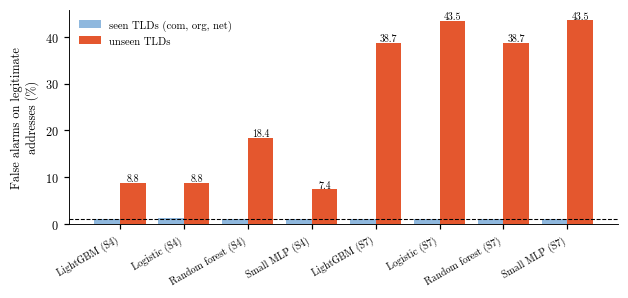

In [17]:
sub = tld_table.loc[["S4 address only", "S7 prefix blind"]].reset_index()
sub["label"] = sub.model + np.where(sub.feature_set.str.startswith("S4"), " (S4)", " (S7)")
fig, ax = plt.subplots(figsize=(5.6, 2.6), layout="constrained")
x = np.arange(len(sub))
ax.bar(x - 0.2, 100 * sub.false_alarm_seen, 0.4, color=SKY, label="seen TLDs (com, org, net)")
ax.bar(x + 0.2, 100 * sub.false_alarm_unseen, 0.4, color=OURS, label="unseen TLDs")
for k in x:
    ax.text(k + 0.2, 100 * sub.false_alarm_unseen.iloc[k] + 0.3, f"{100 * sub.false_alarm_unseen.iloc[k]:.1f}", ha="center", fontsize=6.5, fontfamily=BOLD)
ax.axhline(100 * FPR, color="black", lw=0.7, ls="--")
ax.set_xticks(x)
ax.set_xticklabels(sub.label, rotation=30, ha="right", fontsize=6.5)
ax.set_ylabel("False alarms on legitimate\naddresses (%)")
ax.legend(frameon=False, fontsize=7)
save(fig, "b6_unseen_tld")

## 6.12 Bổ sung 4: kích thước, thời gian và độ quan trọng của đặc trưng
Ô dưới đo, cho mười mô hình trên bộ S4 và S7 (seed 0), kích thước khi lưu (kB) và thời gian chấm một địa chỉ (micro giây) trên máy chạy notebook, đặt cạnh tỷ lệ bắt được và ROC-AUC trên nhóm trang chủ.
Cách đọc: một bộ lọc chạy trong tin nhắn cần nhỏ và nhanh. Thời gian phụ thuộc máy nên chỉ để so tương đối. Bảng lưu ở `Outputs/table_cost.csv`.

In [18]:
train, valid, test = split_of("split", 0)
rows = []
for set_name in ["S4 address only", "S7 prefix blind"]:
    cols = SETS[set_name]
    for name in MODELS:
        m = make_models(0)[name].fit(train[cols], train.phishing)
        t0 = time.perf_counter()
        score(m, test[cols])
        us = 1e6 * (time.perf_counter() - t0) / len(test)
        r = lad[(lad.feature_set == set_name) & (lad.model == name)].iloc[0]
        rows.append(dict(feature_set=set_name, model=name, size_kB=len(pickle.dumps(m)) / 1024, microseconds_per_address=us, caught=r.caught, home_roc_auc=r.home_roc_auc))
cost = pd.DataFrame(rows)
cost.round(4).to_csv(OUT + "table_cost.csv", index=False)
print(cost.round(3).to_string(index=False))
s4 = cost[cost.feature_set == "S4 address only"]
note("Supplement 4", "S4 smallest and largest model (kB)", f"{s4.size_kB.min():.1f} and {s4.size_kB.max():.0f}")

    feature_set         model  size_kB  microseconds_per_address  caught  home_roc_auc
S4 address only      Logistic    2.482                     1.153   0.995         0.996
S4 address only    Linear SVM    2.372                     1.102   0.996         0.996
S4 address only          k-NN  24274.8                   119.857   0.995         0.995
S4 address only Decision tree   30.053                      0.43   0.994         0.996
S4 address only Random forest  20636.6                     2.887   0.995         0.997
S4 address only   Extra trees  21990.6                      3.69   0.995         0.997
S4 address only        HistGB  405.395                     1.921   0.996         0.997
S4 address only      LightGBM  1025.96                     3.241   0.997         0.997
S4 address only       XGBoost  757.075                     2.275   0.996         0.997
S4 address only     Small MLP   92.135                     1.129   0.996         0.997
S7 prefix blind      Logistic    2.085     

**Nhận xét:** với bộ S4, logistic và SVM tuyến tính chỉ nặng khoảng 2,4 tới 2,5 kB và chấm một địa chỉ dưới 1 micro giây, nhưng bắt được 99,5% tới 99,6% địa chỉ lừa đảo, ngang LightGBM (1.026 kB) và random forest (khoảng 20 MB). k-NN nặng nhất (khoảng 24 MB, vì phải giữ cả tập huấn luyện) và chậm nhất (khoảng 200 micro giây một địa chỉ).
Kích thước và thời gian không đổi kết luận: trên bộ S4 mô hình nhỏ nhất cũng đủ, vì bài toán chỉ còn là đọc tiền tố.

Ô dưới tính độ quan trọng hoán vị (permutation importance) của LightGBM trên bộ S4 và S7: xáo ngẫu nhiên một cột của 8.000 địa chỉ kiểm thử và đo ROC-AUC giảm bao nhiêu, trên toàn bộ và trên nhóm trang chủ.
Cách đọc: cột càng làm ROC-AUC giảm nhiều thì mô hình càng dựa vào nó. Bảng lưu ở `Outputs/table_permutation_importance.csv`.

In [19]:
imp_rows = []
home_test = test[test.homepage_only == 1].sample(8000, random_state=0)
for set_name in ["S4 address only", "S7 prefix blind"]:
    cols = SETS[set_name]
    m = make_models(0)["LightGBM"].fit(train[cols], train.phishing)
    for where, part in [("all", test.sample(8000, random_state=0)), ("homepage", home_test)]:
        imp = permutation_importance(m, part[cols], part.phishing, scoring="roc_auc", n_repeats=3, random_state=0, n_jobs=1)
        for c, v in zip(cols, imp.importances_mean):
            imp_rows.append(dict(feature_set=set_name, where=where, feature=c, drop_in_roc_auc=v))
imp = pd.DataFrame(imp_rows)
imp.round(5).to_csv(OUT + "table_permutation_importance.csv", index=False)
for (set_name, where), g in imp.groupby(["feature_set", "where"], sort=False):
    print(f"{set_name} | {where}:", g.nlargest(4, "drop_in_roc_auc").set_index("feature").drop_in_roc_auc.round(4).to_dict())

S4 address only | all: {'DomainLength': 0.1311, 'IsHTTPS': 0.1183, 'LetterRatioInURL': 0.0651, 'NoOfOtherSpecialCharsInURL': 0.0041}
S4 address only | homepage: {'IsHTTPS': 0.2035, 'DomainLength': 0.147, 'LetterRatioInURL': 0.0136, 'SpacialCharRatioInURL': 0.0011}
S7 prefix blind | all: {'pb_path_length': 0.0813, 'pb_tld_length': 0.0347, 'pb_digits': 0.0245, 'pb_length': 0.0174}
S7 prefix blind | homepage: {'pb_tld_length': 0.0755, 'pb_host_dots': 0.0296, 'pb_specials': 0.0261, 'pb_digits': 0.0232}


**Nhận xét:** với bộ S4, LightGBM dựa chủ yếu vào hai cột: `DomainLength` (ROC-AUC giảm 0,131 khi xáo) và `IsHTTPS` (giảm 0,118). Trên nhóm trang chủ, `IsHTTPS` lên đầu (giảm 0,204). Cột `DomainLength` tính trên tên miền đầy đủ, gồm cả `www.` (Bước 2, mục 2.5), nên cả hai cột đứng đầu đều mang dấu vết của tiền tố.
Với bộ S7, khi đã có đường dẫn thì cột đường dẫn đứng đầu. Trên nhóm trang chủ, mô hình dựa vào độ dài TLD, số dấu chấm, số ký tự đặc biệt và số chữ số, đúng những khác biệt nhỏ đã thấy ở Bước 4, mục 4.4.

## 6.13 Ghi bảng LaTeX và tệp con số
Ô dưới ghi hai bảng LaTeX cho bài báo (bảng mười mô hình cạnh quy tắc, và bảng thang đặc trưng) vào `Paper/tables/`, rồi lưu lại tệp con số.

In [20]:
def latex(table, path, caption, label, cols, names, fmt):
    """Ghi một bảng LaTeX theo kiểu booktabs, in đậm giá trị tốt nhất của cột đầu."""
    lines = ["\\begin{table}[t]", "\\centering", f"\\caption{{{caption}}}", f"\\label{{{label}}}", "\\begin{tabular}{l" + "r" * len(cols) + "}", "\\toprule",
             " & ".join(["Model"] + names) + " \\\\", "\\midrule"]
    for _, r in table.iterrows():
        lines.append(" & ".join([str(r.model)] + [fmt[c](r[c]) for c in cols]) + " \\\\")
    lines += ["\\bottomrule", "\\end{tabular}", "\\end{table}"]
    open(path, "w", encoding="utf-8").write("\n".join(lines))


pct = lambda v: f"{100 * v:.2f}"
t1 = pd.concat([rule_table.reset_index()[["model", "accuracy_mean", "caught_mean"]].rename(columns={"accuracy_mean": "accuracy", "caught_mean": "caught"}).assign(roc_auc=np.nan, train_s=0.0),
                main[["model", "accuracy", "caught", "roc_auc", "train_s"]]], ignore_index=True)
latex(t1, "../Paper/tables/table_main.tex", "Ten classifiers with all features against hand-written rules, test sets of five stratified splits (mean).", "tab:main",
      ["accuracy", "caught", "roc_auc", "train_s"], ["Accuracy (\\%)", "Caught at 1\\% FA (\\%)", "ROC-AUC", "Train (s)"],
      {"accuracy": pct, "caught": pct, "roc_auc": lambda v: "--" if pd.isna(v) else f"{v:.4f}", "train_s": lambda v: f"{v:.1f}"})
t2 = by_set.reset_index().rename(columns={"feature_set": "model"})
latex(t2, "../Paper/tables/table_ladder.tex", "Feature ladder: mean ROC-AUC over ten models and best share of phishing caught at 1\\% false alarms, on all test addresses and on homepage-only addresses.",
      "tab:ladder", ["n_features", "roc_auc_mean", "caught_best", "home_roc_auc_mean", "home_caught_best"], ["Features", "ROC-AUC", "Caught (\\%)", "Home ROC-AUC", "Home caught (\\%)"],
      {"n_features": lambda v: f"{int(v)}", "roc_auc_mean": lambda v: f"{v:.4f}", "caught_best": pct, "home_roc_auc_mean": lambda v: f"{v:.4f}", "home_caught_best": pct})
pd.DataFrame(NUMBERS).to_csv(OUT + "paper_numbers.csv", index=False)
print("Đã ghi Paper/tables/table_main.tex, table_ladder.tex và", len(NUMBERS), "con số vào Outputs/paper_numbers.csv | thời gian chạy notebook: %.0f s" % (time.time() - START))

Đã ghi Paper/tables/table_main.tex, table_ladder.tex và 26 con số vào Outputs/paper_numbers.csv | thời gian chạy notebook: 224 s


**Tóm tắt Bước 6.** Bảng dưới gom kết quả theo ba câu hỏi nghiên cứu. Các con số nằm trong `Outputs/table_main.csv`, `table_ladder.csv`, `table_homepage.csv`, `table_unseen_tld.csv` và `paper_numbers.csv`.

| STT | Câu hỏi | Trả lời ngắn | Con số chính |
|---|---|---|---|
| 1 | Hai lớp khác nhau thế nào? | Gần như tuyệt đối ở tiền tố, đường dẫn, chỉ số tương đồng và độ trống của trang (Bước 3, 4) | Hai điều kiện viết tay đạt 99,72% độ chính xác, 0% báo động giả |
| 2 | Mô hình nào tốt nhất, có tách được nhau không? | Với đủ đặc trưng, mười mô hình chạm trần và không tách được nhau. Chúng hơn quy tắc khoảng 0,28 điểm phần trăm | ROC-AUC 0,9999 tới 1,0000; độ chính xác 99,89% tới 100% |
| 3 | Con số gần tuyệt đối còn lại bao nhiêu? | Gần như nguyên khi bỏ chỉ số tương đồng, chỉ giữ địa chỉ hay bỏ thống kê TLD. Chỉ sụp khi không thấy tiền tố, nhất là ở nhóm trang chủ. Trên TLD chưa thấy, báo động giả tăng gấp nhiều lần | S7 trên nhóm trang chủ: ROC-AUC tối đa 0,737, bắt 26,0% ở 1% báo động giả; báo động giả trên TLD chưa thấy 7,4% tới 18,4% với S4 |

Bốn thí nghiệm bổ sung không đổi kết luận: chia theo tên miền và dò tham số gần như không đổi điểm số, và mô hình nhỏ nhất (2,4 kB) đủ tốt trên bộ chỉ dùng địa chỉ.